# Importar librería

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 1.Importar datos
El trabajo presentado se basa en un conjunto de datos sobre el rendimiento académico de estudiantes. He indagado sobre muchas bases y sitios antes de elegirla. La base fue extraída en el siguiente link https://www.kaggle.com/datasets/ayeshaseherr/student-performance?select=StudentPerformanceFactors.csv
Fui docente universitaria durante casi 40 años, ahora estoy retirada pero sigo interesándome por cuestiones que pueden afectar el rendimiento académico del alumnado. La pregunta central es:

**¿En qué medida el rendimiento en el examen final de los estudiantes está determinado por su entorno sociofamiliar en comparación con sus hábitos personales y conductas de estudio?**

De aquí se desprenden dos ejes de estudio que pude plantear luego de estudiar las variables en la base de datos:

*   Eje de estudio 1:  entorno familiar. Las preguntas al respecto son: ¿Existe un efecto combinado entre el nivel educativo de los padres y los ingresos familiares sobre la nota final? ¿De qué manera influye el nivel de involucramiento de los padres en el rendimiento en el examen?
*   Eje de estudio 2: variables personales del estudiante. Las preguntas asociadas a este eje son: ¿Cómo interactúa el la actividad física con la motivación y el resultado del examen? ¿Existe una relación entre el género del estudiante y su resultado en el examen final? ¿Existe una relación entre las horas de estudio y el resultado del examen final?



In [2]:
dataset = pd.read_csv('/content/StudentPerformanceFactors.csv')



In [3]:
dataset

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


# 2.Exploración estructural

## 2.1.Tamaño del dataset

In [4]:
dataset.shape


(6607, 20)

## 2.2.Información general

In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

Observamos que hay datos nulos en tres variables

## 2.3.Información sobre las columnas

In [6]:
dataset.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

Descripción de las columnas

1. Hours_Studied: horas de estudio por semana
2. Attendance: tasa de asistencia a clase
3. Parental_Involvement: nivel de participación de los padres
4. Access_to_Resources: disponibilidad de materiales
5. Extracurricular_Activities: participación en actividades extracurriculares
6. Sleep_Hours: tiempo promedio de sueño por día
7. Previous_Scores: resultados académicos anteriores
8. Motivation_Level: estado de motivación del estudiante
9. Internet_Access: disponibilidad de internet en el hogar
10. Tutoring_Sessions: sesiones de estudio adicionales
11. Family_Income: ingresos familiares
12. Teacher_Quality: calidad del profesorado
13. School_Type: tipo de escuela
14. Peer_Influence: influencia de los pares
15. Physical_Activity: actividad física (horas por día)
16. Learning_Disabilities: discapacidades en el aprendizaje
17. Parental_Education_Level: nivel de educación de los padres
18. Distance_from_Home: distancia desde la casa
19. Gender: género
20. Exam_Score: puntuación en el examen





## 2.4.Tipo de datos de las columnas

In [7]:
# 1. Aseguramos que trabajamos sobre una copia limpia para evitar Warnings
dataset = dataset.copy()

# 2. Identificamos las columnas que son de tipo 'object'
columnas_object = dataset.select_dtypes(include=['object']).columns

# 3. Las convertimos todas a 'category' en una sola línea
dataset[columnas_object] = dataset[columnas_object].astype('category')

# También convertimos Tutoring_Sessions a categoría
dataset['Tutoring_Sessions'] = dataset['Tutoring_Sessions'].astype('category')

In [8]:
dataset.dtypes

,0
Hours_Studied,int64
Attendance,int64
Parental_Involvement,category
Access_to_Resources,category
Extracurricular_Activities,category
Sleep_Hours,int64
Previous_Scores,int64
Motivation_Level,category
Internet_Access,category
Tutoring_Sessions,category


## 2.5.Observación de las primeras 10 filas

In [9]:
dataset.head(10)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


## 2.6. Observar si hay filas duplicadas

In [10]:
dataset.duplicated().sum()

np.int64(0)

## 2.7. Datos nulos

In [11]:
dataset.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


## 2.8. Estudiar las variables que tienen datos faltantes
Estudio esas variables para saber si saco las filas con datos faltantes o las completo con mediana o de otra manera.

In [12]:
display(dataset['Parental_Education_Level'].value_counts())
display(dataset['Teacher_Quality'].value_counts())
display(dataset['Distance_from_Home'].value_counts())

,count
Parental_Education_Level,
High School,3223
College,1989
Postgraduate,1305


,count
Teacher_Quality,
Medium,3925
High,1947
Low,657


,count
Distance_from_Home,
Near,3884
Moderate,1998
Far,658


## 2.9. Decisión sobre valores nulos
No voy a completar los valores nulos, podría hacerlo con la moda ya que hay categorías más frecuentes que otras, pero como tengo 6607 registros optamos por sacar las filas con valores faltantes.

In [13]:
dataset=dataset.dropna()

### Verificación sobre la existencia de valores nulos y el tamaño del nuevo dataset

In [14]:
dataset.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


In [15]:
##Verificamos cuántas filas nos quedan. Teníamos 6607 registros y, por este resultado nos quedan 6378, eliminamos 229 filas

dataset.shape

(6378, 20)

##2.10. Creación de un Identificador único por Estudiante

Me ayudé con IA para crear una columna de identificador llamada `Student_ID`. Ésta asigna un identificador único a cada estudiante en nuestro dataset limpio.

In [16]:
# Creamos una columna de identificadores únicos basados en el índice secuencial
dataset = dataset.reset_index(drop=True)
dataset.insert(0, 'Student_ID', [f'EST_{i+1:04d}' for i in range(len(dataset))])

# Mostramos las primeras filas para verificar la nueva columna
display(dataset[['Student_ID', 'Hours_Studied', 'Gender', 'Exam_Score']].head(10))

,Student_ID,Hours_Studied,Gender,Exam_Score
0,EST_0001,23,Male,67
1,EST_0002,19,Female,61
2,EST_0003,24,Male,74
3,EST_0004,29,Male,71
4,EST_0005,19,Female,70
5,EST_0006,19,Male,71
6,EST_0007,29,Male,67
7,EST_0008,25,Male,66
8,EST_0009,17,Male,69
9,EST_0010,23,Male,72


## 2.11. Revisión de columnas constantes

Me ayudé con IA para hacer una verificación para confirmar si existen columnas en el dataset que contengan un único valor constante para todos los registros. Si existieran, estas variables no aportarían información útil para el análisis y deberían ser descartadas.

In [17]:
# Contamos la cantidad de valores únicos en cada columna del dataset
valores_unicos = dataset.nunique()

# Creamos un DataFrame para visualizar los resultados de forma clara
revision_constantes = pd.DataFrame({
    'Columna': valores_unicos.index,
    'Valores Únicos': valores_unicos.values,
    '¿Es Constante?': valores_unicos.values == 1
})

display(revision_constantes)

,Columna,Valores Únicos,¿Es Constante?
0,Student_ID,6378,False
1,Hours_Studied,41,False
2,Attendance,41,False
3,Parental_Involvement,3,False
4,Access_to_Resources,3,False
5,Extracurricular_Activities,2,False
6,Sleep_Hours,7,False
7,Previous_Scores,51,False
8,Motivation_Level,3,False
9,Internet_Access,2,False


# 3.Exploración estadística inicial

## 3.1.Datos numéricos

In [18]:
dataset.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Physical_Activity,Exam_Score
count,6378.000000,6378.000000,6378.000000,6378.000000,6378.000000,6378.000000
mean,19.977109,80.020853,7.034964,75.066165,2.972719,67.252117
std,5.985460,11.550723,1.468033,14.400389,1.028926,3.914217
min,1.000000,60.000000,4.000000,50.000000,0.000000,55.000000
25%,16.000000,70.000000,6.000000,63.000000,2.000000,65.000000
50%,20.000000,80.000000,7.000000,75.000000,3.000000,67.000000
75%,24.000000,90.000000,8.000000,88.000000,4.000000,69.000000
max,44.000000,100.000000,10.000000,100.000000,6.000000,101.000000


Basándome en cuestiones universalmente reconocidas como las notas de un examen, observo que hay uno o más valores que no pueden corresponder a la misma (101). Me ayudo con IA para identificar cuántos hay y dependiendo de eso qué hacer.

In [19]:
# Filtramos el dataset para encontrar al estudiante o estudiantes con un Exam_Score de 101
estudiantes_anomalos = dataset[dataset['Exam_Score'] == 101]
display(estudiantes_anomalos)

,Student_ID,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,...,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1466,EST_1467,27,98,Low,Medium,Yes,6,93,Low,No,...,High,High,Public,Positive,3,No,High School,Moderate,Female,101


Como solamente un estudiante tiene esta nota (101) considero cambiarla por 100. Es una decisión propia ya que en el sitio del cual bajé el dataset no hay información sobre la escala del examen.

In [20]:
# Corregimos el valor atípico de 101 a 100 en la fila 1525
dataset.loc[1525, 'Exam_Score'] = 100

# Verificamos que el cambio se haya realizado correctamente
display(dataset.loc[[1525]])

,Student_ID,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,...,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,EST_1526,23,78,High,Low,Yes,6,93,Medium,Yes,...,Medium,High,Private,Positive,5,No,Postgraduate,Near,Male,100


In [21]:
dataset.corr(numeric_only=True)

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Physical_Activity,Exam_Score
Hours_Studied,1.000000,-0.004997,0.013119,0.022492,0.003183,0.443302
Attendance,-0.004997,1.000000,-0.019602,-0.018083,-0.022976,0.576913
Sleep_Hours,0.013119,-0.019602,1.000000,-0.023238,-0.002898,-0.017921
Previous_Scores,0.022492,-0.018083,-0.023238,1.000000,-0.006694,0.174830
Physical_Activity,0.003183,-0.022976,-0.002898,-0.006694,1.000000,0.027367
Exam_Score,0.443302,0.576913,-0.017921,0.174830,0.027367,1.000000


In [22]:
data_set_limpio=dataset

In [23]:
data_set_limpio.to_csv('data_set_limpio.csv', index=False)

In [24]:
from google.colab import files
files.download('data_set_limpio.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3.1.1. Primeras observaciones (Datos numéricos)


1.   La cantidad de horas de estudio semanales en promedio es 20 horas, coincidiendo con la mediana. Tiene valores mínimo y máximo muy distantes (1 y 44 horas respectivamente)
2.   El promedio de la tasa de asistencia a clase es de un 80%, coincidente con la mediana, con un mínimo de 60% y un máximo de 100%.
3. Los estudiantes duermen un promedio de 7 horas diarias
4. La nota promedio del examen previo es 75 puntos con un mínimo de 50 y un máximo de 100.
5. En promedio hacen 3 horas de actividad física por día.
6. El promedio de notas del examen final es de 67,25; con una mediana de 67 puntos.
7. Prácticamente no hay correlación lineal entre las variables, salvo la asistencia a clase con la puntuación del examen final (0,58) y en menor medida las horas de estudio con la puntuación del examen final (0,44)


## 3.2. Datos categóricos
Me ayudé con IA para este código

In [25]:
resumen = []
# Seleccionamos únicamente las columnas categóricas
columnas_categoricas = data_set_limpio.select_dtypes(include=['category']).columns

for col in columnas_categoricas:
    # Frecuencia relativa en porcentaje (%)
    freq_rel = data_set_limpio[col].value_counts(normalize=True) * 100
    for categoria, porcentaje in freq_rel.items():
        resumen.append(
            {
                "Variable": col,
                "Categoría": categoria,
                "Porcentaje (%)": round(porcentaje, 2),
            }
        )

data_set_limpio_resumen = pd.DataFrame(resumen)
display(data_set_limpio_resumen)

,Variable,Categoría,Porcentaje (%)
0,Parental_Involvement,Medium,50.97
1,Parental_Involvement,High,28.79
2,Parental_Involvement,Low,20.24
3,Access_to_Resources,Medium,50.24
4,Access_to_Resources,High,29.79
5,Access_to_Resources,Low,19.97
6,Extracurricular_Activities,Yes,59.69
7,Extracurricular_Activities,No,40.31
8,Motivation_Level,Medium,50.75
9,Motivation_Level,Low,29.23


### 3.2.1. Primeras observaciones (datos categóricos)


1.   La mayoría de estudiantes (92%) tiene acceso a internet y el 90% no tiene discapacidades en el aprendizaje.
2.  Las demás variables las voy a analizar con herramientas de visualización



# 4.Visualización
Como primera medida hago un histograma de la variable puntaje en el examen para observar cómo se comporta. Es decir, realizo una exploración para mí, sin una pregunta determinada.


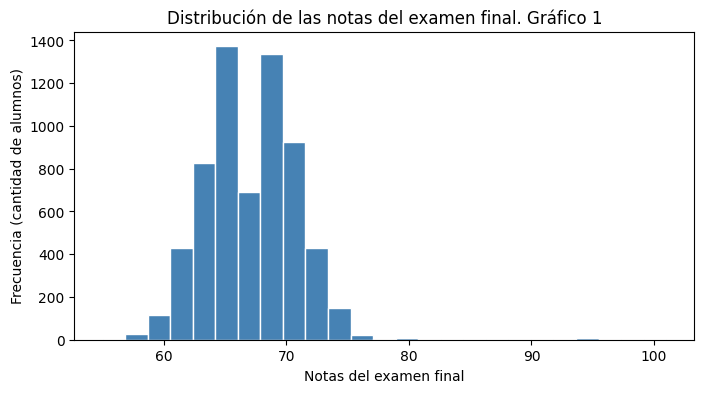

In [26]:
plt.figure(figsize=(8, 4))
plt.hist(data_set_limpio["Exam_Score"], bins=25, color="steelblue", edgecolor="white")
plt.title("Distribución de las notas del examen final. Gráfico 1")
plt.xlabel("Notas del examen final")
plt.ylabel("Frecuencia (cantidad de alumnos)")
plt.show()

La mayoría de los estudiantes tienen nota de examen final entre 64 y 71 puntos aproximadamente. Muy pocos estudiantes (no se logra visualizar bien en el gráfico) tienen notas superiores a 80 puntos

## 4.1. Eje de estudio entre entorno familiar y rendimiento académico
Preguntas que formulé al respecto:
¿Existe un efecto combinado entre el nivel educativo de los padres (Parental_Education_Level) y los ingresos familiares (Family_Income) sobre la nota final?
¿Puede un alto involucramiento de los padres aumentar el rendimiento en el examen?



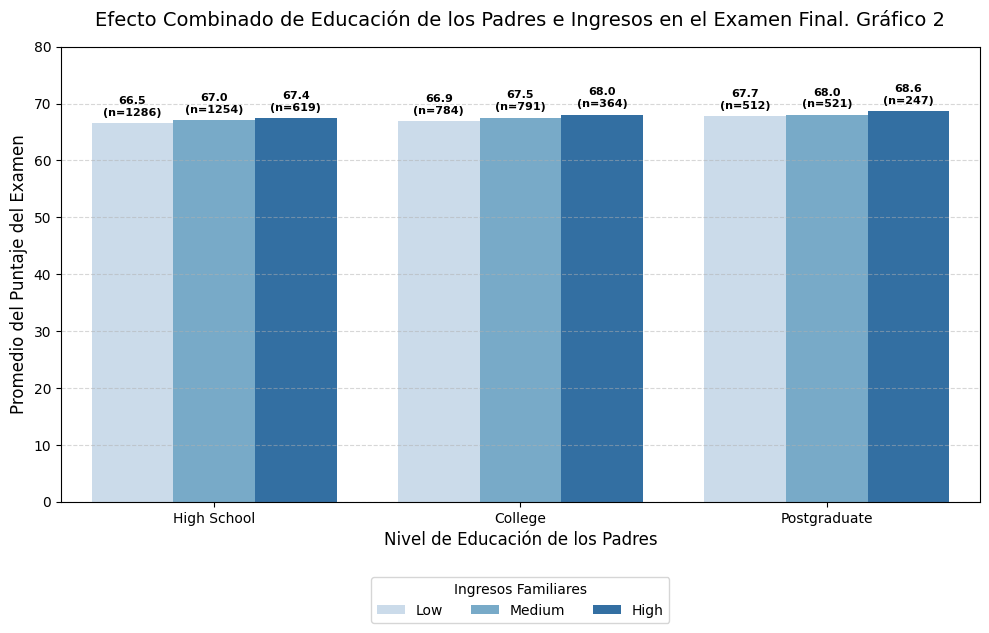

In [27]:
# Definimos un orden lógico para las categorías para facilitar la lectura del gráfico
education_order = ['High School', 'College', 'Postgraduate']
income_order = ['Low', 'Medium', 'High']

# Calculamos los conteos para agregarlos a las etiquetas de las barras
counts = data_set_limpio.groupby(['Parental_Education_Level', 'Family_Income'], observed=False).size().to_dict()

# Configuración del gráfico (ajustamos un poco el tamaño para dar espacio abajo)
plt.figure(figsize=(10, 6.5))
ax = sns.barplot(
    data=data_set_limpio,
    x='Parental_Education_Level',
    y='Exam_Score',
    hue='Family_Income',
    order=education_order,
    hue_order=income_order,
    palette='Blues',
    errorbar=None  # Remueve las barras de error para simplificar la visualización
)

# Personalización
plt.title('Efecto Combinado de Educación de los Padres e Ingresos en el Examen Final. Gráfico 2', fontsize=14, pad=15)
plt.xlabel('Nivel de Educación de los Padres', fontsize=12)
plt.ylabel('Promedio del Puntaje del Examen', fontsize=12)

# Colocamos la leyenda centrada abajo del gráfico para que no obstruya la vista
plt.legend(title='Ingresos Familiares', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.ylim(0, 80) # Subimos a 80 para dar un poco más de aire para el texto

# Mostrar valores y cantidad de alumnos (n) encima de cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        # Determinamos a qué grupo pertenece la barra según su posición x en el gráfico
        x_center = p.get_x() + p.get_width() / 2.
        # Mapeamos la coordenada X de la barra para saber qué educación e ingreso representa
        # Ancho total por grupo de educación es ~1.0. Las sub-barras se ordenan: Low, Medium, High
        group_idx = int(round(x_center))
        bar_sub_idx = 0 if (x_center - group_idx) < -0.15 else (2 if (x_center - group_idx) > 0.15 else 1)

        edu_cat = education_order[group_idx]
        inc_cat = income_order[bar_sub_idx]
        count_val = counts.get((edu_cat, inc_cat), 0)

        # Anotamos el promedio y la cantidad de alumnos (n)
        ax.annotate(f'{height:.1f}\n(n={count_val})',
                    (x_center, height),
                    ha='center', va='center',
                    xytext=(0, 12),
                    textcoords='offset points',
                    fontsize=8,
                    color='black',
                    weight='bold')

plt.tight_layout()
plt.show()

Me ayudé con IA para conocer la cantidad de registros para cada uno de los casos combinados. Me propuso la tabla que doy a continuación

In [28]:
# Creamos una tabla resumen para conocer la cantidad de alumnos (count) y el promedio (mean) de notas por grupo
resumen_grupos = data_set_limpio.groupby(['Parental_Education_Level', 'Family_Income'], observed=False)['Exam_Score'].agg(['count', 'mean']).reset_index()

# Renombramos las columnas para que sea más claro
resumen_grupos.columns = ['Educación de los Padres', 'Ingresos Familiares', 'Cantidad de Alumnos', 'Promedio de Nota']

# Ordenamos la tabla para que coincida con el orden visual del gráfico
education_map = {cat: i for i, cat in enumerate(education_order)}
income_map = {cat: i for i, cat in enumerate(income_order)}

resumen_grupos['orden_edu'] = resumen_grupos['Educación de los Padres'].map(education_map)
resumen_grupos['orden_inc'] = resumen_grupos['Ingresos Familiares'].map(income_map)
resumen_grupos = resumen_grupos.sort_values(by=['orden_edu', 'orden_inc']).drop(columns=['orden_edu', 'orden_inc'])

# Mostramos el resultado
display(resumen_grupos)

,Educación de los Padres,Ingresos Familiares,Cantidad de Alumnos,Promedio de Nota
0,College,High,364,68.041209
1,College,Low,784,66.859694
2,College,Medium,791,67.538559
3,High School,High,619,67.418417
4,High School,Low,1286,66.496112
5,High School,Medium,1254,67.045455
6,Postgraduate,High,247,68.607287
7,Postgraduate,Low,512,67.740234
8,Postgraduate,Medium,521,67.957774


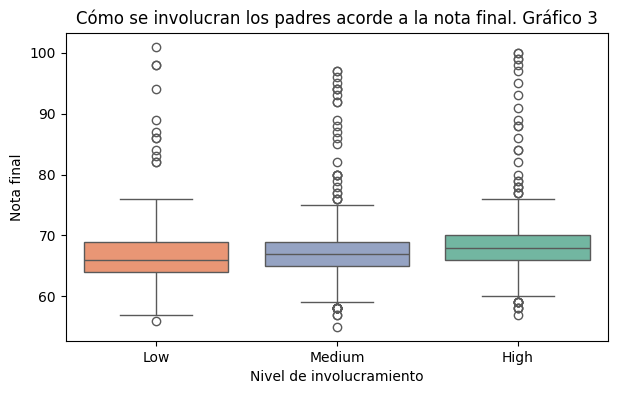

In [29]:
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=data_set_limpio,
    x="Parental_Involvement",
    y="Exam_Score",
    hue="Parental_Involvement",
    order=['Low', 'Medium', 'High'],
    palette="Set2",
    legend=False
)
plt.title("Cómo se involucran los padres acorde a la nota final. Gráfico 3")
plt.xlabel("Nivel de involucramiento")
plt.ylabel("Nota final")
plt.show()

### 4.1.1.Interpretación de los gráficos.


1.   Según lo visto en el Gráfico 2 y su tabla correspondiente, puedo deducir que el nivel educativo de los padres y los ingresos del grupo familiar no tienen mayor incidencia en el rendimiento del estudiante. Si bien hay una distinción sutil entre los promedios de las notas mirando el nivel educativo y el de ingresos, es sólo de 1 punto. Aproximadamente un 50% de los estudiantes tienen padres con nivel secundario, un 30% universitario y un 20% posgrado. Respecto al nivel económico aproximadamente el 40% de las familias de los alumnos tienen nivel bajo, otro 40% medio y sólo un 20% alto.
2.   Respecto al gráfico 2, interpreto que si el involucramiento de los padres es alto mejora la nota del examen final del estudiante. La caja verde tiene mayor mediana, el 50% de los estudiantes se ubica en notas sensiblemente superiores a las demás y también hay varios casos atípicos con notas altas.



##4.2.Eje de estudio sobre cuestiones personales y rendimiento académico
Preguntas que formulé:
¿Cómo interactúa el la actividad física con la motivación y el resultado del examen?
¿Existe una relación entre el género del estudiante y su resultado en el examen final?
¿Existe una relación entre las horas de estudio y el resultado del examen final?


In [30]:
# 1. Definimos el orden lógico para el nivel de motivación
orden_motivacion = ['Low', 'Medium', 'High']

# 2. Aplicamos la conversión a categoría ordenada
data_set_limpio['Motivation_Level'] = pd.Categorical(
    data_set_limpio['Motivation_Level'],
    categories=orden_motivacion,
    ordered=True
)

# Verificamos que la columna ahora esté ordenada
print("Categorías de Motivation_Level ordenadas:")
print(data_set_limpio['Motivation_Level'].dtype)

Categorías de Motivation_Level ordenadas:
category


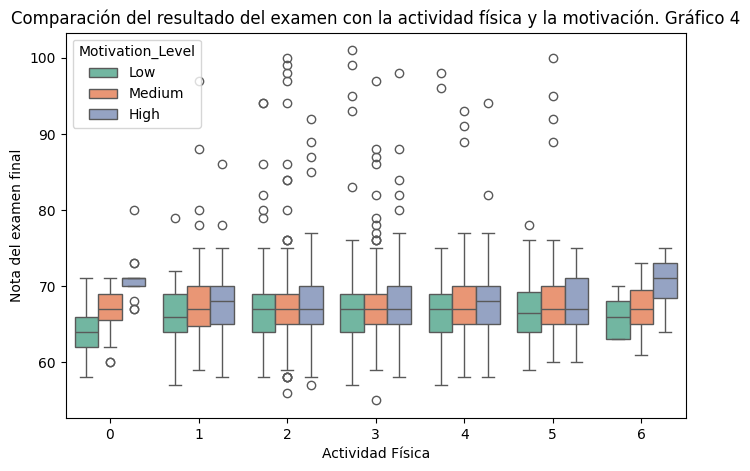

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data_set_limpio, x="Physical_Activity", y="Exam_Score", hue="Motivation_Level", palette="Set2")
plt.title("Comparación del resultado del examen con la actividad física y la motivación. Gráfico 4")
plt.xlabel("Actividad Física")
plt.ylabel("Nota del examen final")
plt.show()

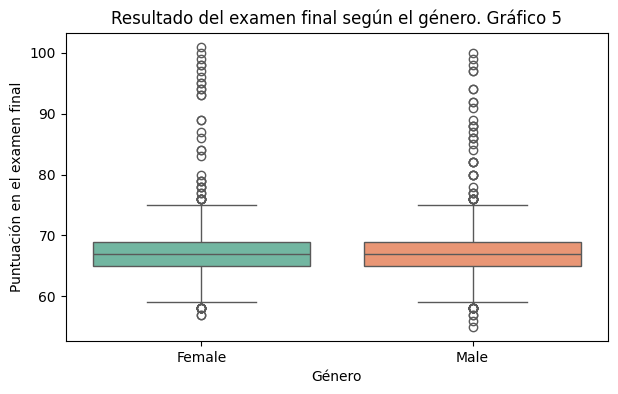

In [32]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=data_set_limpio, x="Gender", y="Exam_Score", hue="Gender", palette="Set2", legend=False)
plt.title("Resultado del examen final según el género. Gráfico 5")
plt.xlabel("Género")
plt.ylabel("Puntuación en el examen final")
plt.show()

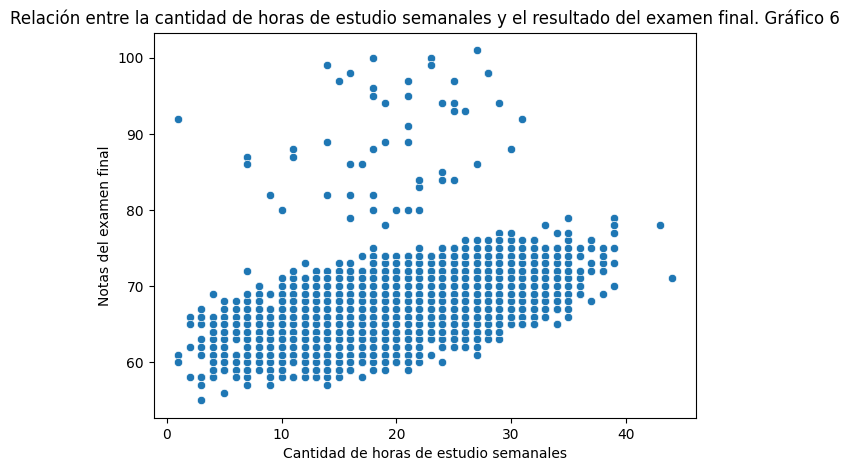

In [33]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=data_set_limpio, x="Hours_Studied", y="Exam_Score")
plt.title("Relación entre la cantidad de horas de estudio semanales y el resultado del examen final. Gráfico 6")
plt.xlabel("Cantidad de horas de estudio semanales")
plt.ylabel("Notas del examen final")
plt.show()

### 4.2.1.Interpretación de los resultados


1.   Del gráfico 4 infiero que los valores de la nota del examen final son similares para estudiantes que hacen actividad física entre 1 y 5 horas sin importar el nivel de motivación. Hay dos casos extremos: los que no hacen actividad física y con nivel bajo de motivación tienen las notas más bajas. A su vez los que hacen 6 horas de actividad física y alto nivel de motivación tienen las notas más altas. Mirando el gráfico en su totalidad el nivel de motivación tiene más incidencia en la nota que la cantidad de horas de actividad física.
2.   No existe diferencia en el rendimiento del examen final según el género del estudiante
3.   Con respecto al gráfico 6 hay una correlación positiva entre la cantidad de horas semanales de estudio y la nota del examen final.



# 5. Discusión de resultados. Conclusiones
Como conclusiones de las variables estudiadas sobre entorno familiar, deduzco que el nivel de involucramiento de los padres tiene incidencia positiva en la nota del examen final, más que el nivel socioeconómico y educativo de ellos.
En cuanto a las variables estudiadas sobre nivel personal, no hay diferencia en la nota final en cuestión de género ni la cantidad de horas de actividad física. Tiene mayor incidencia el nivel de motivación, la asistencia a clase (la cual presentó la correlación más algta en el análisis con un 0.58) ylas horas semanales de estudio (0.44).
Si retomo la pregunta inicial:
**¿En qué medida el rendimiento en el examen final de los estudiantes está determinado por su entorno sociofamiliar en comparación con sus hábitos personales y conductas de estudio?**
De acuerdo a las variables estudiadas tiene mayor incidencia los hábitos personales que el entorno familiar.
